In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn folium jupyter

  Using cached fqdn-1.6.0-py3-none-any.whl.metadata (9.4 kB)
  Using cached isoduration-20.11.0-py3-none-any.whl.metadata (5.7 kB)
  Using cached rfc3987_syntax-1.1.0-py3-none-any.whl.metadata (7.7 kB)
  Using cached uri_template-1.3.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached webcolors-25.10.0-py3-none-any.whl.metadata (2.2 kB)
  Using cached lark-1.3.1-py3-none-any.whl.metadata (1.8 kB)
Using cached rfc3987_syntax-1.1.0-py3-none-any.whl (8.0 kB)
Using cached lark-1.3.1-py3-none-any.whl (113 kB)
Using cached webcolors-25.10.0-py3-none-any.whl (14 kB)
Using cached fqdn-1.6.0-py3-none-any.whl (12 kB)
Using cached isoduration-20.11.0-py3-none-any.whl (11 kB)
Using cached uri_template-1.3.0-py3-none-any.whl (11 kB)

   ---------- ----------------------------- 2/8 [lark]
   ---------- ----------------------------- 2/8 [lark]
   ---------- ----------------------------- 2/8 [lark]
   ------------------------- -------------- 5/8 [branca]
   ------------------------------ --------- 6/8

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
import folium
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("query.csv")

df.head()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2025-11-16T00:00:13.082Z,-55.3691,-27.4837,22.069,4.9,mb,48,67.0,5.318,0.81,...,2026-02-10T15:55:11.040Z,South Sandwich Islands region,earthquake,11.59,5.742,0.083,47.0,reviewed,us,us
1,2025-11-16T02:57:08.203Z,53.1025,159.9097,65.865,4.8,mb,59,126.0,1.324,0.87,...,2026-02-10T15:55:11.040Z,"86 km E of Petropavlovsk-Kamchatsky, Russia",earthquake,10.51,7.069,0.047,142.0,reviewed,us,us
2,2025-11-16T05:33:40.390Z,-10.7082,113.9842,10.000,4.5,mb,28,116.0,2.230,0.56,...,2026-02-10T15:55:17.040Z,"248 km SSW of Jimbaran, Indonesia",earthquake,7.65,1.911,0.124,19.0,reviewed,us,us
3,2025-11-16T06:15:59.381Z,-47.9051,116.1308,10.000,4.5,mb,19,97.0,14.984,0.78,...,2026-02-10T15:55:17.040Z,western Indian-Antarctic Ridge,earthquake,13.93,1.874,0.131,17.0,reviewed,us,us
4,2025-11-16T06:35:39.880Z,6.4774,126.1084,84.568,4.5,mb,39,112.0,0.789,0.58,...,2026-02-10T15:55:11.040Z,"0 km S of Tiblawan, Philippines",earthquake,9.73,6.592,0.090,36.0,reviewed,us,us


In [4]:
print("Rows and Columns:", df.shape)

Rows and Columns: (7805, 22)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7805 entries, 0 to 7804
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             7805 non-null   object 
 1   latitude         7805 non-null   float64
 2   longitude        7805 non-null   float64
 3   depth            7805 non-null   float64
 4   mag              7805 non-null   float64
 5   magType          7805 non-null   object 
 6   nst              7805 non-null   int64  
 7   gap              7803 non-null   float64
 8   dmin             7803 non-null   float64
 9   rms              7805 non-null   float64
 10  net              7805 non-null   object 
 11  id               7805 non-null   object 
 12  updated          7805 non-null   object 
 13  place            7805 non-null   object 
 14  type             7805 non-null   object 
 15  horizontalError  7801 non-null   float64
 16  depthError       7805 non-null   float64
 17  magError      

In [6]:
print(df.columns.tolist())

['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type', 'horizontalError', 'depthError', 'magError', 'magNst', 'status', 'locationSource', 'magSource']


In [7]:
df.isnull().sum()

time                0
latitude            0
longitude           0
depth               0
mag                 0
magType             0
nst                 0
gap                 2
dmin                2
rms                 0
net                 0
id                  0
updated             0
place               0
type                0
horizontalError     4
depthError          0
magError           17
magNst              4
status              0
locationSource      0
magSource           0
dtype: int64

In [8]:
df.columns = df.columns.str.strip().str.lower()

df.head()

,time,latitude,longitude,depth,mag,magtype,nst,gap,dmin,rms,...,updated,place,type,horizontalerror,deptherror,magerror,magnst,status,locationsource,magsource
0,2025-11-16T00:00:13.082Z,-55.3691,-27.4837,22.069,4.9,mb,48,67.0,5.318,0.81,...,2026-02-10T15:55:11.040Z,South Sandwich Islands region,earthquake,11.59,5.742,0.083,47.0,reviewed,us,us
1,2025-11-16T02:57:08.203Z,53.1025,159.9097,65.865,4.8,mb,59,126.0,1.324,0.87,...,2026-02-10T15:55:11.040Z,"86 km E of Petropavlovsk-Kamchatsky, Russia",earthquake,10.51,7.069,0.047,142.0,reviewed,us,us
2,2025-11-16T05:33:40.390Z,-10.7082,113.9842,10.000,4.5,mb,28,116.0,2.230,0.56,...,2026-02-10T15:55:17.040Z,"248 km SSW of Jimbaran, Indonesia",earthquake,7.65,1.911,0.124,19.0,reviewed,us,us
3,2025-11-16T06:15:59.381Z,-47.9051,116.1308,10.000,4.5,mb,19,97.0,14.984,0.78,...,2026-02-10T15:55:17.040Z,western Indian-Antarctic Ridge,earthquake,13.93,1.874,0.131,17.0,reviewed,us,us
4,2025-11-16T06:35:39.880Z,6.4774,126.1084,84.568,4.5,mb,39,112.0,0.789,0.58,...,2026-02-10T15:55:11.040Z,"0 km S of Tiblawan, Philippines",earthquake,9.73,6.592,0.090,36.0,reviewed,us,us


In [9]:
if 'id' in df.columns:
    df = df.drop_duplicates(subset='id')
else:
    df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (7805, 22)


In [10]:
df = df.dropna(
    subset=['latitude', 'longitude', 'mag']
)

print("Shape after removing missing values:", df.shape)

Shape after removing missing values: (7805, 22)


In [11]:
df['latitude'] = pd.to_numeric(
    df['latitude'], errors='coerce'
)

df['longitude'] = pd.to_numeric(
    df['longitude'], errors='coerce'
)

df['mag'] = pd.to_numeric(
    df['mag'], errors='coerce'
)

df['depth'] = pd.to_numeric(
    df['depth'], errors='coerce'
)

df = df.dropna(
    subset=['latitude', 'longitude', 'mag']
)

In [12]:
df = df[
    (df['latitude'] >= -90) &
    (df['latitude'] <= 90) &
    (df['longitude'] >= -180) &
    (df['longitude'] <= 180)
]

print("Final cleaned shape:", df.shape)

Final cleaned shape: (7805, 22)


In [13]:
df['time'] = pd.to_datetime(
    df['time'],
    errors='coerce',
    utc=True
)

df = df.dropna(subset=['time'])

df.head()

,time,latitude,longitude,depth,mag,magtype,nst,gap,dmin,rms,...,updated,place,type,horizontalerror,deptherror,magerror,magnst,status,locationsource,magsource
0,2025-11-16 00:00:13.082000+00:00,-55.3691,-27.4837,22.069,4.9,mb,48,67.0,5.318,0.81,...,2026-02-10T15:55:11.040Z,South Sandwich Islands region,earthquake,11.59,5.742,0.083,47.0,reviewed,us,us
1,2025-11-16 02:57:08.203000+00:00,53.1025,159.9097,65.865,4.8,mb,59,126.0,1.324,0.87,...,2026-02-10T15:55:11.040Z,"86 km E of Petropavlovsk-Kamchatsky, Russia",earthquake,10.51,7.069,0.047,142.0,reviewed,us,us
2,2025-11-16 05:33:40.390000+00:00,-10.7082,113.9842,10.000,4.5,mb,28,116.0,2.230,0.56,...,2026-02-10T15:55:17.040Z,"248 km SSW of Jimbaran, Indonesia",earthquake,7.65,1.911,0.124,19.0,reviewed,us,us
3,2025-11-16 06:15:59.381000+00:00,-47.9051,116.1308,10.000,4.5,mb,19,97.0,14.984,0.78,...,2026-02-10T15:55:17.040Z,western Indian-Antarctic Ridge,earthquake,13.93,1.874,0.131,17.0,reviewed,us,us
4,2025-11-16 06:35:39.880000+00:00,6.4774,126.1084,84.568,4.5,mb,39,112.0,0.789,0.58,...,2026-02-10T15:55:11.040Z,"0 km S of Tiblawan, Philippines",earthquake,9.73,6.592,0.090,36.0,reviewed,us,us


In [14]:
df.describe()

,latitude,longitude,depth,mag,nst,gap,dmin,rms,horizontalerror,deptherror,magerror,magnst
count,7805.000000,7805.000000,7805.000000,7805.000000,7805.000000,7803.000000,7803.000000,7805.000000,7801.000000,7805.000000,7788.000000,7801.000000
mean,1.643836,51.007393,59.413953,4.813775,64.275208,97.809884,4.624758,0.753821,9.242391,3.709826,0.089427,57.981413
std,28.919764,119.210393,109.080109,0.370279,45.961738,43.295892,5.638426,0.221744,3.133118,2.820489,0.038968,72.186530
min,-67.468600,-179.997000,1.000000,4.500000,0.000000,9.000000,0.031550,0.120000,0.000000,0.000000,0.000000,0.000000
25%,-18.075600,-66.877300,10.000000,4.500000,32.000000,66.000000,1.667000,0.600000,7.280000,1.868000,0.061000,19.000000
50%,-0.392000,120.669900,10.000000,4.700000,53.000000,95.000000,2.969000,0.730000,9.060000,1.920000,0.083000,34.000000
75%,23.394700,143.196200,58.348000,5.000000,82.000000,127.000000,5.595000,0.890000,11.040000,5.773000,0.110000,66.000000
max,86.723600,179.989900,665.993000,7.800000,516.000000,323.000000,55.307000,1.810000,54.080000,31.610000,0.400000,874.000000


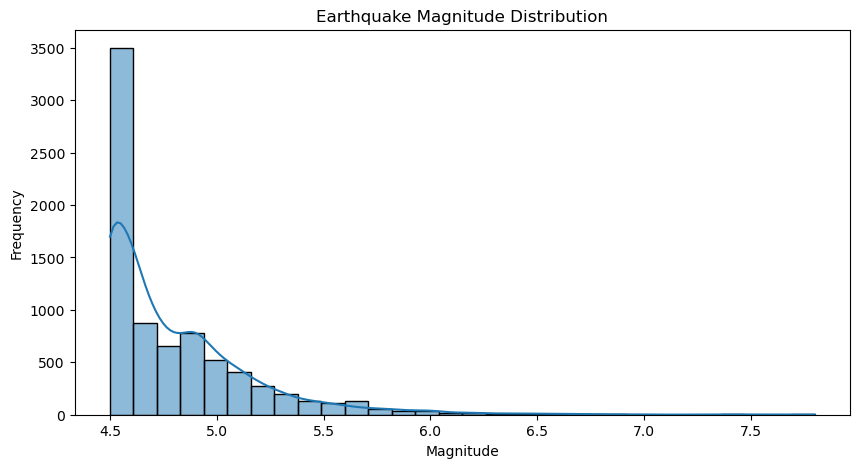

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['mag'],
    bins=30,
    kde=True
)

plt.title("Earthquake Magnitude Distribution")
plt.xlabel("Magnitude")
plt.ylabel("Frequency")

plt.show()

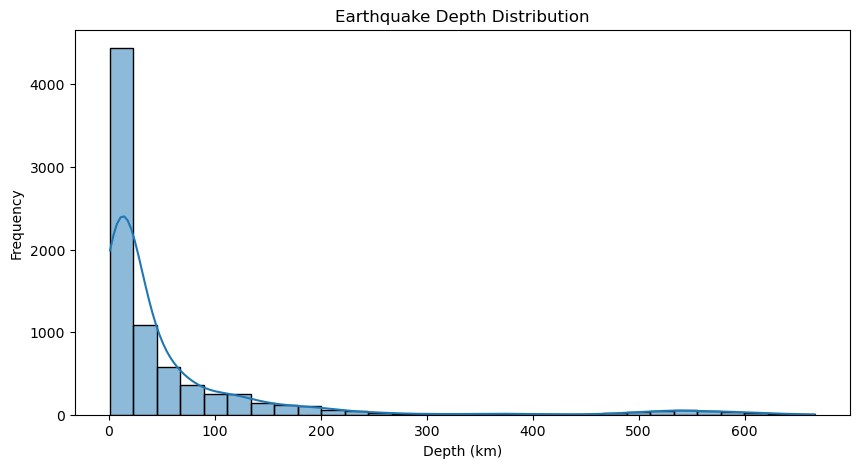

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['depth'].dropna(),
    bins=30,
    kde=True
)

plt.title("Earthquake Depth Distribution")
plt.xlabel("Depth (km)")
plt.ylabel("Frequency")

plt.show()

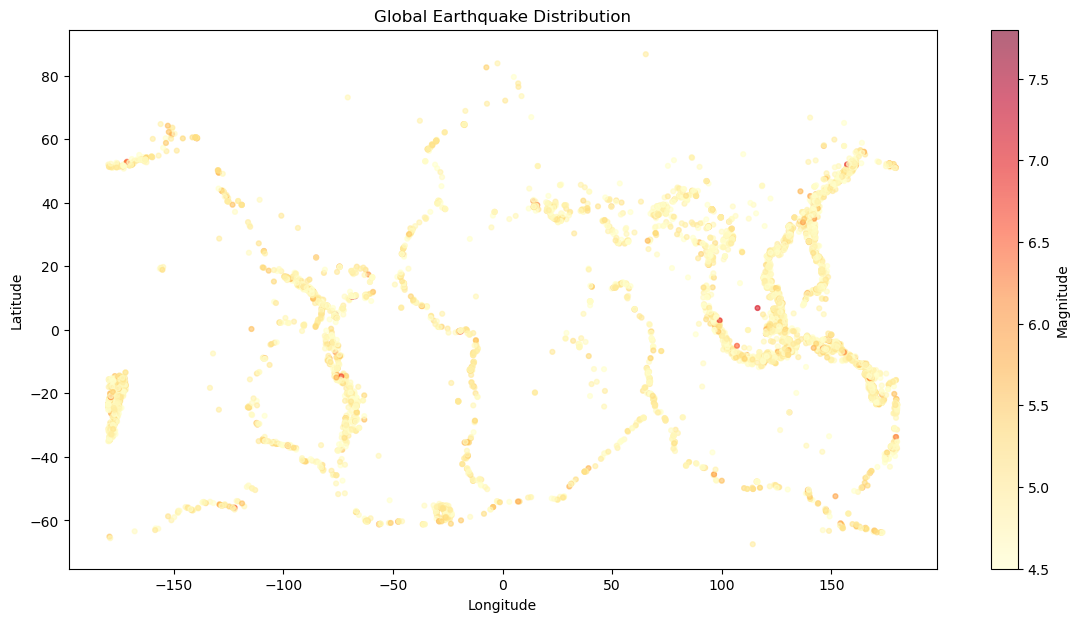

In [17]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df['longitude'],
    df['latitude'],
    c=df['mag'],
    cmap='YlOrRd',
    s=12,
    alpha=0.6
)

plt.colorbar(label="Magnitude")

plt.title("Global Earthquake Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

In [18]:
coordinates = df[
    ['latitude', 'longitude']
].values

In [21]:
coordinates_rad = np.radians(coordinates)
print(coordinates_rad[:5])

[[-0.9663731  -0.47968106]
 [ 0.92681347  2.79095077]
 [-0.18689335  1.98939959]
 [-0.83610172  2.02686482]
 [ 0.11305196  2.20100679]]


In [22]:
earth_radius = 6371.0088
print("Earth radius:", earth_radius, "km")

Earth radius: 6371.0088 km


In [23]:
neighbors = NearestNeighbors(
    n_neighbors=5,
    metric='haversine',
    algorithm='ball_tree'
)

neighbors.fit(coordinates_rad)

distances, indices = neighbors.kneighbors(
    coordinates_rad
)

distances = np.sort(
    distances[:, 4]
)

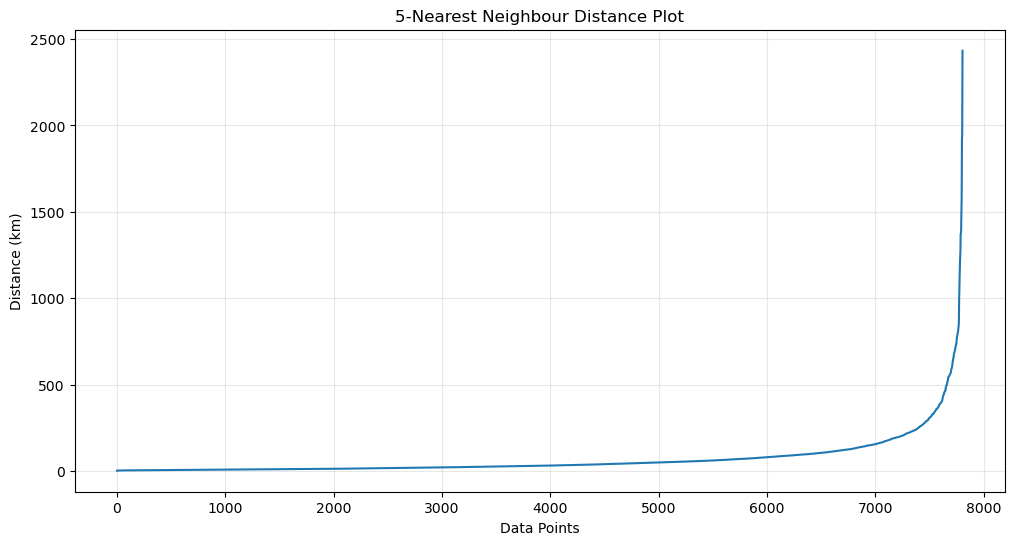

In [24]:
distances_km = distances * earth_radius

plt.figure(figsize=(12, 6))
plt.plot(distances_km)
plt.title("5-Nearest Neighbour Distance Plot")
plt.xlabel("Data Points")
plt.ylabel("Distance (km)")
plt.grid(alpha=0.3)
plt.show()

In [25]:
eps_values = [25, 50, 75, 100]

results = []

for eps_km in eps_values:

    model = DBSCAN(
        eps=eps_km / earth_radius,
        min_samples=5,
        metric='haversine',
        algorithm='ball_tree'
    )

    labels = model.fit_predict(coordinates_rad)

    n_clusters = len(set(labels)) - (
        1 if -1 in labels else 0
    )

    noise_points = np.sum(labels == -1)

    noise_percentage = (
        noise_points / len(labels)
    ) * 100

    results.append({
        'Epsilon_km': eps_km,
        'Clusters': n_clusters,
        'Noise_Points': noise_points,
        'Noise_Percentage': round(noise_percentage, 2)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Epsilon_km,Clusters,Noise_Points,Noise_Percentage
0,25,198,3779,48.42
1,50,207,2274,29.14
2,75,191,1511,19.36
3,100,164,1069,13.70


In [26]:
eps_km = 50

dbscan = DBSCAN(
    eps=eps_km / earth_radius,
    min_samples=5,
    metric='haversine',
    algorithm='ball_tree'
)

df['Cluster'] = dbscan.fit_predict(
    coordinates_rad
)

print("DBSCAN model completed!")

DBSCAN model completed!


In [27]:
n_clusters = len(
    set(df['Cluster'])
) - (1 if -1 in df['Cluster'].values else 0)

print("Number of clusters:", n_clusters)

Number of clusters: 207


In [28]:
noise_points = np.sum(
    df['Cluster'] == -1
)

print("Noise points:", noise_points)

print(
    "Noise percentage:",
    round(noise_points / len(df) * 100, 2),
    "%"
)

Noise points: 2274
Noise percentage: 29.14 %


In [29]:
cluster_distribution = (
    df['Cluster']
    .value_counts()
    .sort_index()
)

display(cluster_distribution)

Cluster
-1      2274
 0        86
 1       367
 2         7
 3       634
        ... 
 202       6
 203       4
 204       6
 205      24
 206       5
Name: count, Length: 208, dtype: int64

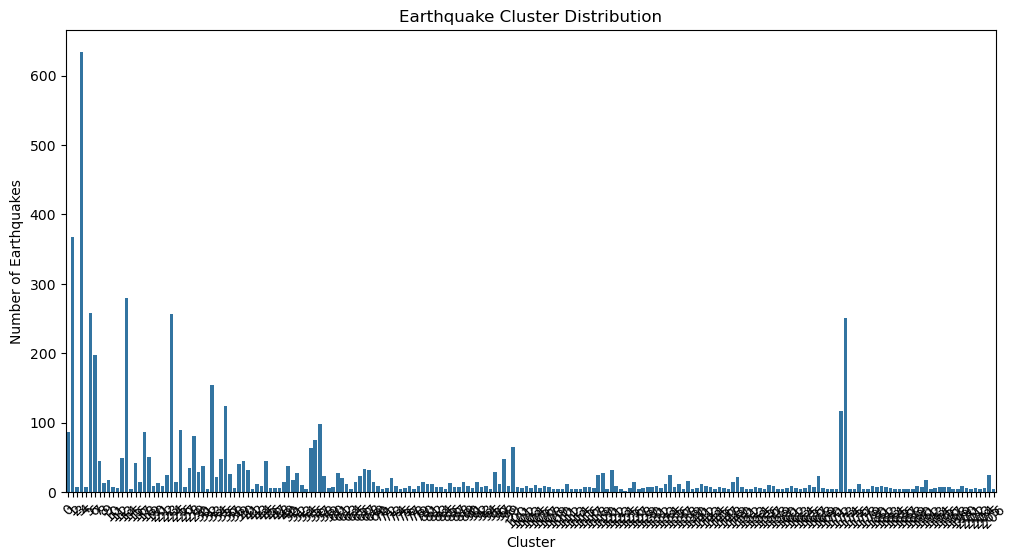

In [30]:
plt.figure(figsize=(12, 6))

cluster_counts = (
    df[df['Cluster'] != -1]['Cluster']
    .value_counts()
    .sort_index()
)

sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values
)

plt.title("Earthquake Cluster Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Earthquakes")

plt.xticks(rotation=45)

plt.show()

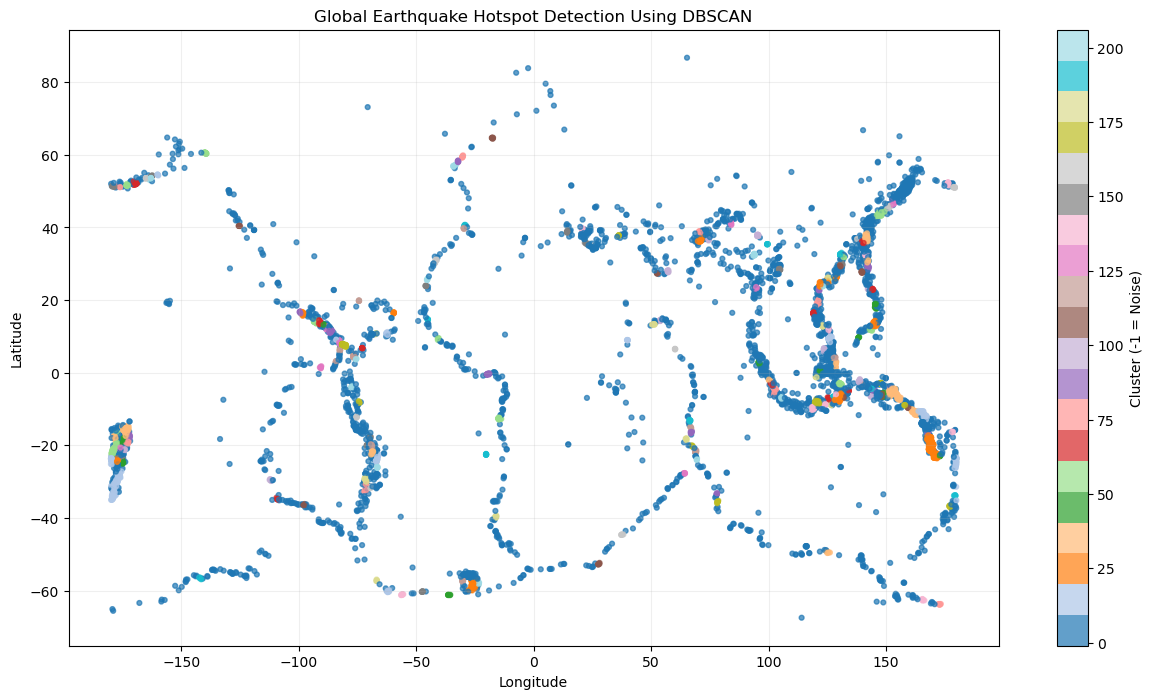

In [31]:
plt.figure(figsize=(15, 8))

scatter = plt.scatter(
    df['longitude'],
    df['latitude'],
    c=df['Cluster'],
    cmap='tab20',
    s=12,
    alpha=0.7
)

plt.colorbar(
    scatter,
    label='Cluster (-1 = Noise)'
)

plt.title("Global Earthquake Hotspot Detection Using DBSCAN")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.grid(alpha=0.2)

plt.show()

In [33]:
cluster_summary = df[
    df['Cluster'] != -1
].groupby('Cluster').agg(
    Number_of_Earthquakes=('Cluster', 'count'),
    Mean_Latitude=('latitude', 'mean'),
    Mean_Longitude=('longitude', 'mean'),
    Median_Magnitude=('mag', 'median'),
    Median_Depth=('depth', 'median')
).round(2)

display(cluster_summary)

,Number_of_Earthquakes,Mean_Latitude,Mean_Longitude,Median_Magnitude,Median_Depth
Cluster,,,,,
0,86,-55.86,-27.36,4.70,35.00
1,367,51.30,158.86,4.70,30.89
2,7,-47.80,116.06,4.50,10.00
3,634,3.86,125.99,4.70,35.00
4,7,12.81,143.31,4.70,153.80
...,...,...,...,...,...
202,6,23.91,122.97,4.65,22.87
203,4,-58.04,-23.35,4.50,10.00
204,6,53.41,-163.31,4.70,21.02
